# Figure 1: North Dakota, race partition, age

Draws Figure 1 of the paper, which is also panel (f) of Figure 9: per-group risk (left) and relative improvement (right) as functions of the slope $\beta$, for white and non-white workers in North Dakota with age as the only feature.

Writes `../figures_final/fig1_analog_ND_race_binary_AGEP_employed.pdf` (and PNG).

In [1]:
import numpy as np
import importlib
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

import folktables_utils
import train_methods
importlib.reload(folktables_utils)
importlib.reload(train_methods)

from folktables_utils import load_acs_income
from train_methods import (
    solve_weighted_groups_closed_form,
    train_group_oracles,
    compute_baseline_losses,
)
YEAR = 2018
lambdas = np.linspace(0, 1, 10001)
OUT_DIR = '../figures_final'


## Data, baseline and group oracles

In [2]:
STATE = "ND"
GROUP_BY = "race_binary"
FEATURES = ["AGEP"]

X, y, g, num_groups, _ = load_acs_income(
    states=(STATE,), year=YEAR, group_by=GROUP_BY, features=FEATURES,
    employed_only=True
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"State: {STATE}, Feature: {FEATURES}")
print(f"Group 0 (White): n={(g==0).sum()}")
print(f"Group 1 (Non-White): n={(g==1).sum()}")

Removed 3370 samples with NaN values
Filtered to full-time year-round employed (ESR==1, WKHP>=35, WKW==1): 4506 -> 2785
Removed 5 samples with non-positive income
Selected 1 features: ['AGEP']
Loaded 2780 samples, 1 features, 2 groups (group_by=race_binary)
State: ND, Feature: ['AGEP']
Group 0 (White): n=2549
Group 1 (Non-White): n=231


In [3]:
baseline = compute_baseline_losses(y, g, num_groups)
oracle = train_group_oracles(
    X_scaled, y, g, num_groups=num_groups, closed_form=True, verbose=True
)

gap = baseline - oracle

print(f"\n{'':=<50}")
print(f"{'Group':<12} {'Baseline':<12} {'Oracle':<12} {'Gap':<12} {'Gap %':<12}")
print(f"{'':=<50}")
for gid, gname in [(0, 'White'), (1, 'Non-White')]:
    gap_pct = 100 * gap[gid] / baseline[gid]
    print(f"{gname:<12} {baseline[gid]:<12.4f} {oracle[gid]:<12.4f} {gap[gid]:<12.4f} {gap_pct:<10.1f}%")
print(f"\nGap ratio (G0/G1): {gap[0]/gap[1]:.2f}x")

Oracle for group 0 (closed-form OLS), n=2549
  Oracle RMSE_0* = 0.7361
Oracle for group 1 (closed-form OLS), n=231
  Oracle RMSE_1* = 0.6208

Group        Baseline     Oracle       Gap          Gap %       
White        0.7436       0.7361       0.0076       1.0       %
Non-White    0.6957       0.6208       0.0749       10.8      %

Gap ratio (G0/G1): 0.10x


## Pareto frontier and method solutions

In [4]:
# Pareto frontier
cp = np.array([
    solve_weighted_groups_closed_form(X_scaled, y, g, num_groups, lam)[2]
    for lam in lambdas
])

n1 = (g == 1).sum()
erm_lam = n1 / len(g)
erm_idx = np.argmin(np.abs(lambdas - erm_lam))

dro_idx = np.argmin(cp.max(axis=1))

regrets = cp - oracle[np.newaxis, :]
mmr_idx = np.argmin(regrets.max(axis=1))

ri = (baseline[np.newaxis, :] - cp) / gap[np.newaxis, :]
mri_idx = np.argmax(ri.min(axis=1))

surplus = baseline[np.newaxis, :] - cp
nash_prod = np.prod(surplus, axis=1)
nash_prod[~np.all(surplus > 0, axis=1)] = -np.inf
nash_idx = np.argmax(nash_prod)
mmv_val = surplus.copy()
mmv_val[~np.all(surplus > 0, axis=1)] = -np.inf
mmv_idx = np.argmax(mmv_val.min(axis=1))


methods = {
    'ERM': cp[erm_idx], 'GDRO': cp[dro_idx], 'MMR': cp[mmr_idx],
    'MMRI': cp[mri_idx], 'Nash': cp[nash_idx],
    'MMV': cp[mmv_idx],
}

print(f"{'Method':<8} {'G0 RMSE':<12} {'G1 RMSE':<12} {'G0 RI':<10} {'G1 RI':<10}")
print("-" * 52)
for name, r in methods.items():
    ri_g0 = (baseline[0] - r[0]) / gap[0] if gap[0] > 0 else 0
    ri_g1 = (baseline[1] - r[1]) / gap[1] if gap[1] > 0 else 0
    print(f"{name:<8} {r[0]:<12.4f} {r[1]:<12.4f} {ri_g0:<10.2%} {ri_g1:<10.2%}")

Method   G0 RMSE      G1 RMSE      G0 RI      G1 RI     
----------------------------------------------------
ERM      0.7365       0.6695       94.60%     34.87%    
GDRO     0.7361       0.6799       100.00%    21.00%    
MMR      0.7492       0.6339       -73.61%    82.46%    
MMRI     0.7393       0.6530       56.92%     56.90%    
Nash     0.7376       0.6608       80.02%     46.56%    
MMV      0.7361       0.6799       100.00%    21.00%    


## Risk and relative improvement as functions of $\beta$

In [5]:
# Extract beta(lambda)
betas_p = np.zeros(len(lambdas))
for i, lam in enumerate(lambdas):
    coef_i, intercept_i, _ = solve_weighted_groups_closed_form(
        X_scaled, y, g, num_groups, lam
    )
    betas_p[i] = coef_i[0]

mask0 = (g == 0)
mask1 = (g == 1)
reg0 = LinearRegression().fit(X_scaled[mask0], y[mask0])
reg1 = LinearRegression().fit(X_scaled[mask1], y[mask1])
bs0 = reg0.coef_[0]
bs1 = reg1.coef_[0]

r0_b = cp[:, 0]
r1_b = cp[:, 1]
rho0_b = (baseline[0] - r0_b) / gap[0]
rho1_b = (baseline[1] - r1_b) / gap[1]

beta_mmr = betas_p[mmr_idx]
beta_mri = betas_p[mri_idx]
beta_mmv = betas_p[mmv_idx]

print(f"beta*_0 (White) = {bs0:.4f}")
print(f"beta*_1 (Non-White) = {bs1:.4f}")
print(f"beta_MMR = {beta_mmr:.4f}, RI: G0={rho0_b[mmr_idx]:.2%}, G1={rho1_b[mmr_idx]:.2%}")
print(f"beta_MMRI = {beta_mri:.4f}, RI: G0={rho0_b[mri_idx]:.2%}, G1={rho1_b[mri_idx]:.2%}")

beta*_0 (White) = 0.1029
beta*_1 (Non-White) = 0.1455
beta_MMR = 0.1444, RI: G0=-73.61%, G1=82.46%
beta_MMRI = 0.1279, RI: G0=56.92%, G1=56.90%


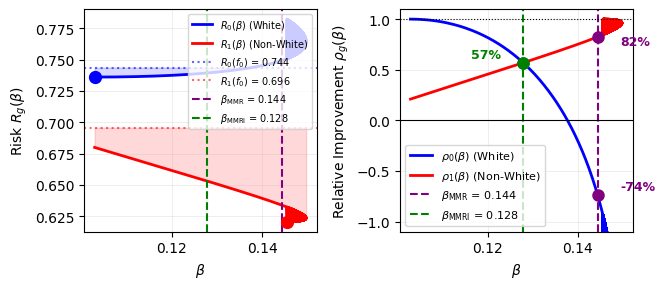

In [6]:
si_b = np.argsort(betas_p)
bs = betas_p[si_b]
r0s = r0_b[si_b]; r1s = r1_b[si_b]
rho0s = rho0_b[si_b]; rho1s = rho1_b[si_b]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.75, 3))

ax1.plot(bs, r0s, color='blue', linewidth=2, label=r'$R_0(\beta)$ (White)')
ax1.plot(bs, r1s, color='red', linewidth=2, label=r'$R_1(\beta)$ (Non-White)')
ax1.axhline(baseline[0], color='blue', linestyle=':', linewidth=1.5, alpha=0.6,
            label=f'$R_0(f_0)$ = {baseline[0]:.3f}')
ax1.axhline(baseline[1], color='red', linestyle=':', linewidth=1.5, alpha=0.6,
            label=f'$R_1(f_0)$ = {baseline[1]:.3f}')
ax1.scatter(bs0, oracle[0], color='blue', s=64, zorder=5, edgecolors='blue', linewidths=1.5)
ax1.scatter(bs1, oracle[1], color='red', s=64, zorder=5, edgecolors='red', linewidths=1.5)
ax1.axvline(beta_mmr, color='purple', linestyle='--', linewidth=1.5,
            label=f'$\\beta_{{\\mathrm{{MMR}}}}$ = {beta_mmr:.3f}')
ax1.axvline(beta_mri, color='green', linestyle='--', linewidth=1.5,
            label=f'$\\beta_{{\\mathrm{{MMRI}}}}$ = {beta_mri:.3f}')
ax1.fill_between(bs, r0s, baseline[0], where=(r0s < baseline[0]), alpha=0.15, color='blue')
ax1.fill_between(bs, r1s, baseline[1], where=(r1s < baseline[1]), alpha=0.15, color='red')
ax1.set_xlabel(r'$\beta$')
ax1.set_ylabel(r'Risk $R_g(\beta)$')
ax1.legend(loc='upper right', fontsize=7, ncol=1)
ax1.grid(True, alpha=0.3, linewidth=0.5)

ax2.plot(bs, rho0s, color='blue', linewidth=2, label=r'$\rho_0(\beta)$ (White)')
ax2.plot(bs, rho1s, color='red', linewidth=2, label=r'$\rho_1(\beta)$ (Non-White)')
ax2.axvline(beta_mmr, color='purple', linestyle='--', linewidth=1.5,
            label=f'$\\beta_{{\\mathrm{{MMR}}}}$ = {beta_mmr:.3f}')
ax2.axvline(beta_mri, color='green', linestyle='--', linewidth=1.5,
            label=f'$\\beta_{{\\mathrm{{MMRI}}}}$ = {beta_mri:.3f}')

# MMR annotations
ri_mmr_0 = rho0_b[mmr_idx]
ri_mmr_1 = rho1_b[mmr_idx]
ax2.scatter(beta_mmr, ri_mmr_0, color='purple', s=64, zorder=5)
ax2.scatter(beta_mmr, ri_mmr_1, color='purple', s=64, zorder=5)
ax2.annotate(f'{ri_mmr_0:.0%}', xy=(beta_mmr, ri_mmr_0),
             xytext=(beta_mmr+0.005, ri_mmr_0+0.05), fontsize=9, color='purple', weight='bold')
ax2.annotate(f'{ri_mmr_1:.0%}', xy=(beta_mmr, ri_mmr_1),
             xytext=(beta_mmr+0.005, ri_mmr_1-0.08), fontsize=9, color='purple', weight='bold')

# MMRI annotations
ri_mri_0 = rho0_b[mri_idx]
ri_mri_1 = rho1_b[mri_idx]
ax2.scatter(beta_mri, ri_mri_0, color='green', s=64, zorder=5)
ax2.scatter(beta_mri, ri_mri_1, color='green', s=64, zorder=5)
ax2.annotate(f'{ri_mri_0:.0%}', xy=(beta_mri, ri_mri_0),
             xytext=(beta_mri-0.005, ri_mri_0+0.05), fontsize=9, color='green', weight='bold',
             ha='right')

# Adjust ylim to fit all data
rho_min = -1
ax2.axhline(y=0, color='black', linewidth=0.8)
ax2.axhline(y=1, color='black', linewidth=0.8, linestyle=':')
ax2.set_ylim(min(-0.05, rho_min - 0.1), 1.1)
ax2.set_xlabel(r'$\beta$')
ax2.set_ylabel(r'Relative Improvement $\rho_g(\beta)$')
ax2.legend(loc='lower left', fontsize=8)
ax2.grid(True, alpha=0.3, linewidth=0.5)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig1_analog_ND_race_binary_AGEP_employed.pdf', dpi=300, bbox_inches='tight')
plt.savefig(f'{OUT_DIR}/fig1_analog_ND_race_binary_AGEP_employed.png', dpi=300, bbox_inches='tight')
plt.show()